# M1 mentor roster: check notebook

## Plain-language guide

**Why the study needs this module.** The study asks whether a newcomer who gets a reply from their
assigned mentor keeps editing Wikipedia longer. To answer that, we must first know **who was a mentor,
and when**. M1 builds that list. Later steps use it in three ways: M2 uses it to decide whether a reply
on a mentor's talk page was written by the mentor; M4 uses it to check that the newcomer's mentor was in
the "automatic pool" (the group that the software assigns new accounts to at random) on the day the
newcomer signed up; and the paper reports the number of mentors.

**Raw data and where it comes from.** All raw data comes from English Wikipedia through the public
MediaWiki API (the web interface that returns page history). M1 uses the full edit history (every saved
version, called a "revision") of the pages where mentors sign up:

* `Wikipedia:Growth Team features/Mentor list` (the automatic list, 2021-05-04 to 2022-10-26);
* `Wikipedia:Growth Team features/Mentor list/Manual` (the manual list, counted from 2021-09-20);
* the structured roster page in JSON format, `MediaWiki:GrowthMentors.json` (from 2022-10-26 on);
* the history of the wiki setting that says which page is the manual list, plus a small table that
  turns user names into user ids (a user id, or "uid", is a number that never changes, even when the
  user renames their account).

Only revisions saved strictly before the cutoff, **2026-04-20T14:00:00Z**, are used.

**What the processing does.**

1. Read every roster revision before the cutoff, in time order.
2. For each revision, work out for every mentor one of three states: in the automatic pool, on the
   roster but manual only (newcomers can pick them, but the software does not assign them), or not on
   the roster.
3. Turn user names into user ids, so a mentor who renamed their account is still one person.
4. Each time a mentor's state changes, record an event (joined, left, or moved in or out of the pool).
5. Join consecutive revisions with the same state into time periods, and count the mentors on the
   roster at the end of every month.

**What it produces** (numbers from this run on the final data, cutoff 2026-04-20T14:00Z):

* `mentor_list.parquet`: **450 rows**, one per mentor. Key columns: the user id, the latest user name,
  when they first joined and last left, whether they are still on the roster at the cutoff (291 are)
  and whether they are in the automatic pool then (210 are).
* `mentor_periods.parquet`: **825 rows**. One row is a stretch of time during which one mentor's state
  stayed the same: start time, end time (empty if it still holds at the cutoff), and whether that
  state was "automatic pool" or "manual only".
* `mentor_events.parquet`: **1,031 rows**, one per change: the time, the revision number (so anyone can
  open it on Wikipedia), who made the edit, and the kind of change (497 joined, 206 left,
  328 pool changes).
* `mentor_names.parquet`: **489 rows**, one per (mentor, name) pair, so a mentor who used several
  names has several rows. M2 uses it to recognize a mentor's signature.
* `monthly_pool.csv`: **59 rows**, one per month from 2021-05 to 2026-03, with the number of mentors
  listed, in the automatic pool, and manual only.

### How to read this notebook

* All outputs below are already saved from a full run. **You do not need to run anything.**
* Each check prints `[OK ]` (the rule holds) or `[FAIL]` (it does not, which would need explanation).
* An **invariant** is a rule that must always be true of the data, such as "a period never ends
  before it starts".
* A **replay** (section 3.2) is a second, independent rebuild of the roster from the raw revisions,
  written here in simple code. If the replay and M1 agree for every mentor, the M1 code is very
  unlikely to have a bug.
* A **tracer** is a mentor chosen in advance and followed through every module, so the same people
  can be compared across notebooks. A **random sample** is drawn with a fixed seed (a number that
  makes the draw repeatable), so nobody chose the examples by hand.
* Links in the outputs open the exact Wikipedia revision, so any claim can be checked by eye.

## 1. What this module does

**Code**: `pipeline/m1_roster/` (`collect_roster.py` downloads the raw data, `build_roster.py` rebuilds the roster offline).
**Rules**: DATA_PROCESSING R1.1 to R1.3 (roster formats, cutoff, uid as key) and R6.1 to R6.3 (names and uids).

Growth mentors sign up on a roster page. The roster had three formats over time:

1. **Wikitext period** (2021-05-04 to 2022-10-26). Two pages. A line `* [[User:Name]]|intro` on
   `Wikipedia:Growth Team features/Mentor list` means the mentor is in the **automatic pool** (new
   accounts are assigned to them at random). The same line on `.../Mentor list/Manual` means the mentor
   can only be claimed by hand. The manual page only counts while the wiki setting points to it
   (from 2021-09-20). If someone is on both pages, the automatic page wins.
2. **JSON period with `automaticallyAssigned`** (from 2022-10-26): `{"Mentors": {uid: {username, weight, automaticallyAssigned}}}`.
3. **JSON period with only `weight`**: weight 0 means "not in the automatic pool".

M1 replays every revision of these pages before the cutoff (2026-04-20T14:00:00Z) and writes four tables:
`mentor_list` (one row per mentor), `mentor_periods` (time spans with a constant status),
`mentor_events` (joined / left / auto_pool_change) and `mentor_names` (every name a mentor used).

**Paper numbers that depend on it**: whether the assigned mentor was in the automatic pool when the newcomer
registered (M4 sample eligibility, D10); who counts as a mentor when M2 labels a reply; the number of mentors (Sec 3.1).

## How to use this notebook

* The saved outputs come from a full run. To rerun, run all cells from the top (about 1 minute).
  Every check prints `[OK ]` or `[FAIL]`.
* Section 3 replays the raw revisions with **separate, simple code written in this notebook** and compares
  the result with M1 for all mentors. Section 5 shows random mentors in detail, with links to the
  exact revisions where their status changed, so you can open them on Wikipedia.
* Change `SEED` in the next cell to draw a new random sample.

**What this checks.** The next cell only loads the five M1 output tables and prints how many rows
each has. It is a quick sanity check that the files exist and are not empty.

In [1]:
# ── setup ────────────────────────────────────────────────────────────────────
SEED = 0          # change this number to draw a fresh random sample in section 5
N_RANDOM = 5      # how many random mentors / names to show

import json, re, sys, html as _html
from collections import defaultdict
from pathlib import Path
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import config
from pipeline.common.io import read_jsonl, iter_jsonl
from pipeline.common.tracer import tracer_frame
from checks._show import Checks, compare, pick, oldid, diff, contribs, logid
pd.set_option("display.max_colwidth", 100); pd.set_option("display.width", 200)
M1 = config.INTERIM / "m1"
RAW1 = config.RAW / "m1_roster"
CUTOFF = config.DATA_CUTOFF_ISO
ml = pd.read_parquet(M1 / "mentor_list.parquet")
periods = pd.read_parquet(M1 / "mentor_periods.parquet")
events = pd.read_parquet(M1 / "mentor_events.parquet")
names = pd.read_parquet(M1 / "mentor_names.parquet")
mp = pd.read_csv(config.RESULTS / "m1" / "monthly_pool.csv").set_index("month")
print(f"mentors {len(ml)} | periods {len(periods)} | events {len(events)} | names {len(names)} | months {len(mp)}")

mentors 450 | periods 825 | events 1031 | names 489 | months 59


**What the output shows.** On the final data (cutoff 2026-04-20T14:00Z) there are 450 mentors,
825 periods, 1,031 events, 489 names and 59 months. These are the sizes used throughout this notebook.

## 2. Files and manifest

**What this checks.** M1 writes a "manifest", a small receipt that lists which input files it read
(with size and date), which files it wrote, the cutoff it used, and its main counts. This shows the
outputs were made from the expected inputs with the right cutoff.

In [2]:
man = json.loads((M1 / "manifest.json").read_text())
print("finished:", man["finished_at"], "| cutoff:", man["data_cutoff"], "| elapsed:", man["elapsed_sec"], "s")
display(pd.DataFrame(man["inputs"])[["path", "exists", "bytes", "mtime"]])
display(pd.DataFrame(man["outputs"])[["path", "bytes"]])
print(json.dumps(man["counts"], ensure_ascii=False, indent=1))

finished: 2026-10-26T01:51:36.513684+00:00 | cutoff: 2026-04-20T14:00:00Z | elapsed: 3.7 s


,path,exists,bytes,mtime
0,./data/input/roster/roster_revisions...,True,3085805,2026-06-17T20:06:50.046230+00:00
1,./data/input/roster/roster_revisions...,True,126158149,2026-06-17T20:06:51.814592+00:00
2,./data/input/roster/roster_uid_map.json,True,2931,2026-06-17T20:07:11.295206+00:00
3,./data/input/roster/earlier_frozen_m...,True,260852,2026-07-16T02:40:49.455566+00:00
4,./data/raw/m1_roster/manual_list_rev...,True,45526,2026-10-07T13:17:03.889476+00:00
5,./data/raw/m1_roster/config_revision...,True,462,2026-10-07T13:17:03.889949+00:00
6,./data/raw/m1_roster/uid_map_extra.json,True,664,2026-10-07T13:17:03.890335+00:00


,path,bytes
0,./data/interim/m1/mentor_list.parquet,29698
1,./data/interim/m1/mentor_periods.par...,33672
2,./data/interim/m1/mentor_events.parquet,66759
3,./data/interim/m1/mentor_names.parquet,21719
4,./results/m1/monthly_pool.csv,1094
5,./results/m1/compare_with_eval2.csv,6306


{
 "mentors": 450,
 "uid_unresolved": 0,
 "current": 291,
 "current_auto": 210,
 "ever_manual_only": 162,
 "only_in_wikitext_manual": 6,
 "events": 1031,
 "periods": 825,
 "names": 489,
 "eval2_compare": {
  "same": 439,
  "first_joined": 9,
  "last_left": 1,
  "first_joined,last_left": 1
 },
 "issues": {
  "transient_pool_state": 108,
  "differs_from_eval2": 11
 }
}


**What the output shows.** The cutoff is 2026-04-20T14:00:00Z as intended, all seven inputs exist, and
M1 took under 4 seconds (it works offline from saved files). Of the 450 mentors, 291 are on the roster
at the cutoff and 210 of those are in the automatic pool; 162 were "manual only" at some time; 6 appear
only on the old manual list. Every name was turned into a user id (`uid_unresolved: 0`). The two issue
counts (108 short-lived states, 11 differences from the older version) are explained in sections 4 and 6.

### Data dictionary

Every output column, what it means, and where this notebook checks it.
"Replay" means the independent replay in section 3.2; "5.R" means the random side-by-side examples in section 5.

In [3]:
DD = {
 "mentor_list": [
  ("mentor_uid", "Wikipedia user id of the mentor (primary key, R1.3)", "3.1 unique; 3.3 replay; 5.R"),
  ("key", "same as mentor_uid as text, or NAME:<name> if no uid was found", "3.1 key == str(uid)"),
  ("username", "the name the mentor had the last time they were seen on the roster", "3.3 replay (last name seen); 5.R"),
  ("uid_resolved", "True if the name could be turned into a uid", "3.1 all True"),
  ("first_joined", "time of the first roster revision that lists the mentor", "3.3 replay; 5.R"),
  ("last_left", "time of the last roster revision that removed the mentor (empty if never removed)", "3.3 replay; 5.R"),
  ("is_current", "still on the roster in the last revision before the cutoff", "3.3 replay; 5.R"),
  ("currently_in_auto_pool", "in the automatic pool in the last revision before the cutoff (empty if not on the roster)", "3.3 replay; 5.R"),
  ("ever_in_auto_pool", "was in the automatic pool at some time", "3.3 replay; 5.R"),
  ("ever_manual_only", "was on the roster but outside the automatic pool at some time", "3.3 replay; 5.R"),
  ("join_count", "number of times the mentor was added to the roster", "3.3 replay; 5.R"),
  ("leave_count", "number of times the mentor was removed from the roster", "3.3 replay; 5.R"),
  ("sources", "which roster formats produced events for this mentor", "3.3 replay; 5.R"),
 ],
 "mentor_periods": [
  ("mentor_uid / key", "the mentor", "3.1 every period belongs to a mentor in mentor_list"),
  ("start", "time the status began (a roster revision time)", "3.3 replay, period by period; 5.R"),
  ("end", "time the status ended (empty: still holds at the cutoff)", "3.3 replay; 3.1 start < end"),
  ("in_auto_pool", "True = automatic pool, False = on the roster but manual only", "3.3 replay; 5.R"),
  ("weight_known", "True if the JSON entry had automaticallyAssigned or weight (always False in the wikitext period)", "3.3 replay"),
  ("source", "roster format of the revision that started the period", "3.3 replay"),
  ("hours", "end minus start in hours", "3.1 recomputed from start and end"),
 ],
 "mentor_events": [
  ("timestamp / revid", "the roster revision where the change happened", "3.1 revid exists in the raw revisions with this timestamp; 5.R links"),
  ("editor / comment", "who saved that revision and their edit summary", "3.1 equal to the raw revision"),
  ("event", "joined, left or auto_pool_change", "3.3 replay (number of events per mentor); 5.R"),
  ("in_auto_pool / in_auto_pool_from", "status after (and before, for auto_pool_change)", "3.1 consistency with periods; 5.R"),
  ("username / mentor_uid / key / source / weight_known", "as above", "3.1, 3.3"),
 ],
 "mentor_names": [
  ("mentor_uid", "the mentor", "3.1 every uid is in mentor_list"),
  ("name", "one normalized name the mentor used (on the roster, in the uid map, or an alt account)", "3.3 replay; 5.N random names"),
  ("first_seen / last_seen", "first and last roster revision that shows this name for this uid (empty for non-roster sources)", "3.3 replay; 5.N"),
  ("source", "roster, uid_map, api_users or alt_account", "5.N shows the raw evidence for each source"),
 ],
 "monthly_pool.csv": [
  ("month / listed / auto_pool / manual_only", "number of mentors on the roster at the last minute of each month, split by pool", "3.3 replay; section 7 public figures"),
 ],
}
for t, rows in DD.items():
    print(f"\n## {t}")
    display(pd.DataFrame(rows, columns=["column", "meaning", "checked in"]))


## mentor_list


,column,meaning,checked in
0,mentor_uid,"Wikipedia user id of the mentor (primary key, R1.3)",3.1 unique; 3.3 replay; 5.R
1,key,"same as mentor_uid as text, or NAME:<name> if no uid was found",3.1 key == str(uid)
2,username,the name the mentor had the last time they were seen on the roster,3.3 replay (last name seen); 5.R
3,uid_resolved,True if the name could be turned into a uid,3.1 all True
4,first_joined,time of the first roster revision that lists the mentor,3.3 replay; 5.R
5,last_left,time of the last roster revision that removed the mentor (empty if never removed),3.3 replay; 5.R
6,is_current,still on the roster in the last revision before the cutoff,3.3 replay; 5.R
7,currently_in_auto_pool,in the automatic pool in the last revision before the cutoff (empty if not on the roster),3.3 replay; 5.R
8,ever_in_auto_pool,was in the automatic pool at some time,3.3 replay; 5.R
9,ever_manual_only,was on the roster but outside the automatic pool at some time,3.3 replay; 5.R



## mentor_periods


,column,meaning,checked in
0,mentor_uid / key,the mentor,3.1 every period belongs to a mentor in mentor_list
1,start,time the status began (a roster revision time),"3.3 replay, period by period; 5.R"
2,end,time the status ended (empty: still holds at the cutoff),3.3 replay; 3.1 start < end
3,in_auto_pool,"True = automatic pool, False = on the roster but manual only",3.3 replay; 5.R
4,weight_known,True if the JSON entry had automaticallyAssigned or weight (always False in the wikitext period),3.3 replay
5,source,roster format of the revision that started the period,3.3 replay
6,hours,end minus start in hours,3.1 recomputed from start and end



## mentor_events


,column,meaning,checked in
0,timestamp / revid,the roster revision where the change happened,3.1 revid exists in the raw revisions with this timestamp; 5.R links
1,editor / comment,who saved that revision and their edit summary,3.1 equal to the raw revision
2,event,"joined, left or auto_pool_change",3.3 replay (number of events per mentor); 5.R
3,in_auto_pool / in_auto_pool_from,"status after (and before, for auto_pool_change)",3.1 consistency with periods; 5.R
4,username / mentor_uid / key / source / weight_known,as above,"3.1, 3.3"



## mentor_names


,column,meaning,checked in
0,mentor_uid,the mentor,3.1 every uid is in mentor_list
1,name,"one normalized name the mentor used (on the roster, in the uid map, or an alt account)",3.3 replay; 5.N random names
2,first_seen / last_seen,first and last roster revision that shows this name for this uid (empty for non-roster sources),3.3 replay; 5.N
3,source,"roster, uid_map, api_users or alt_account",5.N shows the raw evidence for each source



## monthly_pool.csv


,column,meaning,checked in
0,month / listed / auto_pool / manual_only,"number of mentors on the roster at the last minute of each month, split by pool",3.3 replay; section 7 public figures


**What the output shows.** These tables are a reference, not a test: they list every output column in
plain words and say which later section checks it, so no column is left unchecked.

## 3. Invariants

### 3.1 Structure of the output tables

**What this checks.** Basic rules that must hold in any correct roster: every mentor has a unique
user id, nothing happens at or after the cutoff, periods do not overlap and never end before they
start, a mentor still on the roster has exactly one open period, and the counts in `mentor_list`
match the events. If any of these failed, later modules could count a mentor twice or use the wrong
pool status.

In [4]:
ck = Checks()
ck.add("mentor_list has 450 mentors (number at the time this notebook was written)", len(ml) == 450)
ck.add("every name was resolved to a uid", ml.uid_resolved.all())
ck.add("key is unique", ml.key.is_unique)
ck.add("key == str(mentor_uid)", (ml.key == ml.mentor_uid.astype(str)).all())
ck.add("no event at or after the cutoff", (pd.to_datetime(events.timestamp, utc=True) < config.DATA_CUTOFF).all())
ck.add("no mentor joined at or after the cutoff", (pd.to_datetime(ml.first_joined, utc=True) < config.DATA_CUTOFF).all())
ck.add("every period starts before it ends", (periods.end.isna() | (periods.start < periods.end)).all())
ck.add("periods of the same mentor do not overlap",
       all((g.start.iloc[1:].values >= g.end.iloc[:-1].fillna("9999").values).all()
           for _, g in periods.sort_values("start").groupby("key") if len(g) > 1))
ck.add("at most one open period (empty end) per mentor", periods[periods.end.isna()].key.is_unique)
ck.add("is_current == the mentor has an open period",
       set(ml[ml.is_current].key) == set(periods[periods.end.isna()].key))
cur = periods[periods.end.isna()].set_index("key").in_auto_pool
ck.add("currently_in_auto_pool == in_auto_pool of the open period",
       all(ml[ml.is_current].apply(lambda r: r.currently_in_auto_pool == cur[r.key], axis=1)))
ck.add("not current -> currently_in_auto_pool is empty", ml[~ml.is_current].currently_in_auto_pool.isna().all())
h = (pd.to_datetime(periods.end, utc=True) - pd.to_datetime(periods.start, utc=True)).dt.total_seconds() / 3600
ck.add("hours == end - start", ((h - periods.hours).abs().fillna(0) < 1e-6).all() and (h.isna() == periods.hours.isna()).all())
ck.add("every period, event and name belongs to a mentor in mentor_list",
       set(periods.key) <= set(ml.key) and set(events.key) <= set(ml.key) and set(names.mentor_uid) <= set(ml.mentor_uid))
ck.add("join_count == number of joined events", (ml.set_index("key").join_count ==
       events[events.event == "joined"].groupby("key").size().reindex(ml.key).fillna(0).values).all())
ck.add("leave_count == number of left events", (ml.set_index("key").leave_count ==
       events[events.event == "left"].groupby("key").size().reindex(ml.key).fillna(0).values).all())
ck.add("(mentor_uid, name) is unique in mentor_names", not names.duplicated(["mentor_uid", "name"]).any())
ck.add("periods: in_auto_pool is never empty", periods.in_auto_pool.notna().all())

  [OK ] mentor_list has 450 mentors (number at the time this notebook was written)
  [OK ] every name was resolved to a uid
  [OK ] key is unique
  [OK ] key == str(mentor_uid)
  [OK ] no event at or after the cutoff
  [OK ] no mentor joined at or after the cutoff
  [OK ] every period starts before it ends
  [OK ] periods of the same mentor do not overlap
  [OK ] at most one open period (empty end) per mentor
  [OK ] is_current == the mentor has an open period
  [OK ] currently_in_auto_pool == in_auto_pool of the open period
  [OK ] not current -> currently_in_auto_pool is empty
  [OK ] hours == end - start
  [OK ] every period, event and name belongs to a mentor in mentor_list
  [OK ] join_count == number of joined events
  [OK ] leave_count == number of left events
  [OK ] (mentor_uid, name) is unique in mentor_names
  [OK ] periods: in_auto_pool is never empty


True

**What the output shows.** All 18 structural checks print `[OK ]` on the final data
(cutoff 2026-04-20T14:00Z). (The `True` at the end is just the return value of the report.)

### 3.2 Independent replay of the raw roster revisions

The code below does **not** call any M1 function. It reads the three raw revision files and, for each
revision, works out the status of every mentor: `auto` (automatic pool), `manual` (manual only) or absent.
Its parsing rules are written out in plain Python:

* wikitext: remove `<!-- -->` comments, keep lines starting with `*`, take the name after `[[User:`;
  normalize the name (underscores to spaces, first letter upper case, drop `/subpage`);
* the manual page counts only while `config_revisions.jsonl` says the wiki setting points to it;
* JSON: use `automaticallyAssigned` if present, else `weight != 0`;
* names in the wikitext period become uids through the JSON roster itself (which has both), then the old uid map.

**What this checks.** The next cell reads the raw revisions and builds the replay. It prints how many
raw revisions there are and how many mentors the replay finds, which should be 450, like M1.

In [5]:
SWITCH = "2022-10-26T13:19:10Z"     # first revision of the JSON roster (DATA_PROCESSING section 1)

def content(rev):
    m = rev.get("slots", {}).get("main", {})
    return m.get("content", m.get("*", "")) or ""

def my_name(n):
    n = _html.unescape(n).replace("_", " ").split("/")[0]
    n = re.sub(r"[\s ‎‏]+", " ", n).strip()
    return n[:1].upper() + n[1:]

def my_wikitext_names(text):
    text = re.sub(r"<!--.*?-->", "", text, flags=re.S)
    out = []
    for line in text.split("\n"):
        line = line.strip()
        m = re.search(r"\[\[\s*user\s*:\s*([^\]|#]+)", line, flags=re.I) if line.startswith("*") else None
        if m and my_name(m.group(1)) and my_name(m.group(1)) not in out:
            out.append(my_name(m.group(1)))
    return out

def my_json_status(entry):
    if "automaticallyAssigned" in entry: return ("auto" if entry["automaticallyAssigned"] else "manual"), True
    if entry.get("weight") is not None:  return ("auto" if entry["weight"] != 0 else "manual"), True
    return None, False

raw_wiki = [r for r in iter_jsonl(config.EXTERNAL["roster_revisions_wikitext"]) if r["timestamp"] < CUTOFF]
raw_json = [r for r in iter_jsonl(config.EXTERNAL["roster_revisions_json"]) if r["timestamp"] < CUTOFF]
raw_manual = [r for r in read_jsonl(RAW1 / "manual_list_revisions.jsonl") if r["timestamp"] < CUTOFF]
cfg = read_jsonl(RAW1 / "config_revisions.jsonl")
print(f"raw revisions before the cutoff: auto wikitext {len(raw_wiki)}, manual wikitext {len(raw_manual)}, JSON {len(raw_json)}")
print("wiki setting changes for the manual list:", [(c["timestamp"], c["manual_list"]) for c in cfg])

# name -> uid: JSON roster entries first, then the old uid map, then names resolved by collect_roster.py
json_entries = {}                                   # revid -> parsed entries (None if not valid JSON)
for r in raw_json:
    try:
        d = json.loads(content(r)); d = d.get("Mentors", d)
        json_entries[int(r["revid"])] = {k: v for k, v in d.items() if isinstance(v, dict)}
    except (json.JSONDecodeError, AttributeError):
        json_entries[int(r["revid"])] = None
name2uid = {}
for k, v in json.loads((RAW1 / "uid_map_extra.json").read_text()).items():
    if v.get("uid") is not None: name2uid[my_name(k)] = int(v["uid"])
for k, v in json.loads(config.EXTERNAL["roster_uid_map"].read_text()).items():
    if v is not None: name2uid[my_name(k)] = int(v)
for ents in json_entries.values():
    for uid, e in (ents or {}).items():
        if e.get("username") and uid.isdigit(): name2uid[my_name(e["username"])] = int(uid)

def manual_on(ts):
    on = False
    for c in sorted(cfg, key=lambda c: c["timestamp"]):
        if c["timestamp"] <= ts: on = bool(c.get("manual_list"))
    return on

# one snapshot per revision: {uid: (status, weight_known, name)}
seq = [("wikitext_auto", r) for r in raw_wiki if r["timestamp"] < SWITCH] + \
      [("wikitext_manual", r) for r in raw_manual if r["timestamp"] < SWITCH]
seq.sort(key=lambda x: (x[1]["timestamp"], x[0]))
snaps, page_now = [], {"wikitext_auto": [], "wikitext_manual": []}
for src, r in seq:
    page_now[src] = my_wikitext_names(content(r))
    st = {}
    if manual_on(r["timestamp"]):
        for n in page_now["wikitext_manual"]: st[name2uid.get(n, "NAME:" + n)] = ("manual", False, n)
    for n in page_now["wikitext_auto"]: st[name2uid.get(n, "NAME:" + n)] = ("auto", False, n)
    snaps.append((r["timestamp"], int(r["revid"]), src, st))
for r in raw_json:
    ents = json_entries[int(r["revid"])]
    if r["timestamp"] < SWITCH or not ents: continue
    st = {int(u): (*my_json_status(e), my_name(e.get("username") or "")) for u, e in ents.items() if u.isdigit()}
    snaps.append((r["timestamp"], int(r["revid"]), "json", st))
snaps.sort(key=lambda s: s[0])
print("snapshots replayed:", len(snaps), "| JSON revisions that are not valid JSON:",
      sum(v is None for v in json_entries.values()))

# walk through the snapshots and record, for each mentor, every revision where the status changes
timeline = defaultdict(list)      # uid -> [(ts, revid, source, old status, new status)]
name_seen = defaultdict(list)     # (uid, name) -> [ts]
prev = {}
for ts, rid, src, st in snaps:
    for u in set(st) | set(prev):
        old = prev[u][0] if u in prev else "absent"
        new = st[u][0] if u in st else "absent"
        if old != new: timeline[u].append((ts, rid, src, old, new, st[u][1] if u in st else prev[u][1]))
    for u, v in st.items():
        if isinstance(u, int) and v[2]: name_seen[(u, v[2])].append(ts)
    prev = st
final = prev
print("mentors found by the replay:", len(timeline))

raw revisions before the cutoff: auto wikitext 281, manual wikitext 24, JSON 2017
wiki setting changes for the manual list: [('2021-06-28T18:05:54Z', None), ('2021-07-01T08:47:04Z', ''), ('2021-09-20T16:28:04Z', 'Wikipedia:Growth Team features/Mentor list/Manual')]


snapshots replayed: 2277 | JSON revisions that are not valid JSON: 0


mentors found by the replay: 450


**What the output shows.** Before the cutoff there are 281 revisions of the automatic list, 24 of the
manual list and 2,017 of the JSON roster; none of the JSON revisions is broken. The wiki setting history
shows the manual list was switched on only on 2021-09-20 (the two earlier entries are empty), so manual
names before that date are ignored, as the rule says. The replay steps through 2,277 roster versions
(the snapshots) and finds 450 mentors, the same number as M1.

**What this checks (next cell).** It looks for mentors whose JSON entry never had a user name, then
summarizes each mentor from the replay so the next section can compare it field by field with M1.

In [6]:
uid_names = json.loads((RAW1 / "uid_names.json").read_text())     # uid -> name, looked up with the API by collect_roster.py
print("mentors whose JSON entries never had a username:", uid_names)

def my_summary(u):
    """Everything mentor_list and mentor_periods say about one mentor, recomputed from the replay timeline."""
    tl = timeline[u]
    statuses = [x[4] for x in tl if x[4] != "absent"]
    last_name = max(((max(ts), n) for (uu, n), ts in name_seen.items() if uu == u), default=(None, None))[1]
    per, open_ = [], None
    for ts, rid, src, old, new, wk in tl:
        if open_: open_["end"] = ts; per.append(open_); open_ = None
        if new != "absent": open_ = {"start": ts, "end": None, "in_auto_pool": new == "auto", "weight_known": wk, "source": src}
    if open_: per.append(open_)
    if last_name is None:     # no name on the roster (JSON entry without username): the name found by uid through the API
        last_name = uid_names.get(str(u))
    return {"username": last_name,
            "first_joined": next(x[0] for x in tl if x[3] == "absent"),
            "last_left": max((x[0] for x in tl if x[4] == "absent"), default=None),
            "is_current": u in final,
            "currently_in_auto_pool": (final[u][0] == "auto") if u in final else None,
            "ever_in_auto_pool": "auto" in statuses, "ever_manual_only": "manual" in statuses,
            "join_count": sum(x[3] == "absent" for x in tl), "leave_count": sum(x[4] == "absent" for x in tl),
            "sources": ",".join(sorted({x[2] for x in tl})), "periods": per}

def same(a, b):
    """Equal, treating None and NaN as the same empty value."""
    na, nb = a is None or (isinstance(a, float) and pd.isna(a)), b is None or (isinstance(b, float) and pd.isna(b))
    return (na and nb) or (not na and not nb and a == b)

LIST_FIELDS = ["username", "first_joined", "last_left", "is_current", "currently_in_auto_pool",
               "ever_in_auto_pool", "ever_manual_only", "join_count", "leave_count", "sources"]
mine = {u: my_summary(u) for u in timeline}
mli = ml.set_index("mentor_uid")
def data_periods(u):
    return [{"start": r.start, "end": r.end, "in_auto_pool": bool(r.in_auto_pool), "weight_known": bool(r.weight_known),
             "source": r.source} for r in periods[periods.mentor_uid == u].sort_values("start").itertuples()]
mism = []
for u, s in mine.items():
    if u not in mli.index: mism.append((u, "missing from mentor_list", None, None)); continue
    for f in LIST_FIELDS:
        a, b = s[f], mli.loc[u, f]
        if not same(a, b): mism.append((u, f, a, b))
    if s["periods"] != data_periods(u): mism.append((u, "periods", len(s["periods"]), len(data_periods(u))))
for u in set(mli.index) - set(mine): mism.append((u, "in mentor_list but not found by the replay", None, None))
mism = pd.DataFrame(mism, columns=["mentor_uid", "field", "replay", "in data"])

mentors whose JSON entries never had a username: {'40327848': 'Silikonz-alt'}


**What the output shows.** Only one mentor (an alternate account) had a JSON entry with no user name;
its name was looked up by user id through the API. Everything else has a name on the roster itself.

### 3.3 Replay versus M1 output, for every mentor and every month

**What this checks.** The independent replay is compared with M1 for all 450 mentors and every field:
names, join and leave times, current status, pool status, counts and every single period. It also
checks that each event points to a real raw revision with the same time, editor and edit summary, and
that the monthly counts agree. This is the main test of the module: two separate pieces of code must
reach exactly the same roster.

In [7]:
ck.add("replay finds the same set of mentors as mentor_list", set(mine) == set(mli.index))
for f in LIST_FIELDS + ["periods"]:
    n = int((mism.field == f).sum())
    ck.add(f"mentor_list.{f} equals the replay for all mentors (mismatches: {n})" if f != "periods"
           else f"mentor_periods (start, end, in_auto_pool, weight_known, source) equal the replay (mismatching mentors: {n})", n == 0)
if len(mism): print("\nMISMATCH rows:"); display(mism.head(30))

# events: one event per status change in the replay; editor, comment and timestamp come from the raw revision
ck.add("number of events per mentor == number of status changes in the replay",
       events.groupby("mentor_uid").size().to_dict() == {u: len(t) for u, t in timeline.items()})
raw_by_id = {int(r["revid"]): r for r in raw_wiki + raw_manual + raw_json}
ev_ok = events.apply(lambda e: int(e.revid) in raw_by_id and raw_by_id[int(e.revid)]["timestamp"] == e.timestamp
                     and (raw_by_id[int(e.revid)].get("user") or "") == e.editor
                     and (raw_by_id[int(e.revid)].get("comment") or "") == e.comment, axis=1)
ck.add(f"every event's revid, timestamp, editor and comment match the raw revision (bad: {int((~ev_ok).sum())})", ev_ok.all())

# names seen on the roster
nm_roster = names[names.source == "roster"]
nm_ok = nm_roster.apply(lambda r: (r.mentor_uid, r["name"]) in name_seen
                        and min(name_seen[(r.mentor_uid, r["name"])]) == r.first_seen
                        and max(name_seen[(r.mentor_uid, r["name"])]) == r.last_seen, axis=1)
ck.add(f"mentor_names (source roster): name, first_seen, last_seen equal the replay (bad: {int((~nm_ok).sum())})", nm_ok.all())
ck.add("every (uid, name) the replay saw is in mentor_names",
       set(name_seen) <= set(zip(names.mentor_uid, names["name"])))

# month-end counts recomputed from the replay
def count_at(t):
    c = {"listed": 0, "auto_pool": 0, "manual_only": 0}
    for u, s in mine.items():
        for p in s["periods"]:
            if p["start"] <= t and (p["end"] is None or p["end"] > t):
                c["listed"] += 1; c["auto_pool" if p["in_auto_pool"] else "manual_only"] += 1
    return c
mon_bad = []
for m, r in mp.iterrows():
    t = (pd.Timestamp(m + "-01") + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%dT23:59:00Z")
    c = count_at(t)
    if c != {"listed": r.listed, "auto_pool": r.auto_pool, "manual_only": r.manual_only}: mon_bad.append((m, c, r.to_dict()))
ck.add(f"monthly_pool.csv equals month-end counts from the replay (bad months: {len(mon_bad)})", not mon_bad)
for x in mon_bad[:5]: print("  MISMATCH", x)
ck.report()

  [OK ] replay finds the same set of mentors as mentor_list
  [OK ] mentor_list.username equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.first_joined equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.last_left equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.is_current equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.currently_in_auto_pool equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.ever_in_auto_pool equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.ever_manual_only equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.join_count equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.leave_count equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_list.sources equals the replay for all mentors (mismatches: 0)
  [OK ] mentor_periods (start, end, in_auto_pool, weight_known, source) equal the replay (mismatching mentor

  [OK ] monthly_pool.csv equals month-end counts from the replay (bad months: 0)

35 / 35 checks passed


**What the output shows.** All 17 checks print `[OK ]`, with 0 mismatches in every field, 0 bad events
and 0 bad months, so together with section 3.1 all 35 of 35 checks pass on the final data (cutoff
2026-04-20T14:00Z). The replay and M1 agree exactly on every mentor.

## 4. Comparison with the previous version (eval2 frozen roster)

"eval2" is an earlier, frozen version of the same roster made by an older pipeline. Comparing with it
shows what changed and why.
Expected: every difference comes from the **manual list** of the wikitext period (eval2 did not parse it),
or from eval2 using "not later than the cutoff" where M1 uses "strictly before".

**What this checks.** It counts mentors whose join or leave dates differ between M1 and eval2, lists
them, and tests whether each difference is explained by the manual list.

In [8]:
cmp = pd.read_csv(config.RESULTS / "m1" / "compare_with_eval2.csv")
print(cmp.kind.value_counts().to_string())
dfe = pd.DataFrame([{"uid": r["ids"]["uid"], "name": r["ids"]["name"], "kind": r["detail"]["kind"],
                     "new_joined": (r["detail"]["new"] or {}).get("first_joined", "")[:10],
                     "eval2_joined": (r["detail"]["eval2"] or {}).get("first_joined", "")[:10],
                     "new_left": (r["detail"]["new"] or {}).get("last_left", "")[:10],
                     "eval2_left": (r["detail"]["eval2"] or {}).get("last_left", "")[:10],
                     "new_sources": (r["detail"]["new"] or {}).get("sources")}
                    for r in read_jsonl(M1 / "_issues" / "differs_from_eval2.jsonl")])
display(dfe)
expl = dfe.new_sources.fillna("").str.contains("wikitext_manual")
print(f"\ndifferences explained by the manual list (new_sources contains wikitext_manual): {int(expl.sum())} of {len(dfe)}")
print("not explained by the manual list (look at these by hand):")
display(dfe[~expl])

kind
same                      439
first_joined                9
last_left                   1
first_joined,last_left      1


,uid,name,kind,new_joined,eval2_joined,new_left,eval2_left,new_sources
0,502540,Xaosflux,last_left,2021-06-07,2021-06-07,2021-06-07,2022-01-04,"wikitext_auto,wikitext_manual"
1,937895,Andrew Davidson,first_joined,2021-12-20,2022-10-26,None,None,wikitext_manual
2,5661201,Rhododendrites,first_joined,2022-02-18,2022-10-26,None,None,wikitext_manual
3,21731094,Xaosflux ep,first_joined,2021-09-21,2022-10-26,None,None,wikitext_manual
4,22858399,Etonkovidova (WMF),first_joined,2022-08-16,2022-10-26,2025-07-11,2025-07-11,"json,wikitext_manual"
5,30395827,IAmChaos,first_joined,2022-03-30,2022-03-31,None,None,"wikitext_auto,wikitext_manual"
6,33234406,MMiller (WMF),first_joined,2022-02-07,2022-10-26,None,None,wikitext_manual
7,36735309,Martin Urbanec (WMF),"first_joined,last_left",2021-12-07,2022-10-26,2021-12-07,None,wikitext_manual
8,42610765,SGimeno (WMF),first_joined,2022-09-15,2022-10-26,None,None,wikitext_manual
9,43133762,Rusty Cat,first_joined,2022-03-19,2022-05-15,2022-09-02,2022-09-02,"json,wikitext_auto,wikitext_manual"



differences explained by the manual list (new_sources contains wikitext_manual): 11 of 11
not explained by the manual list (look at these by hand):


,uid,name,kind,new_joined,eval2_joined,new_left,eval2_left,new_sources


**What the output shows.** 439 of 450 mentors are identical to eval2. The other 11 differ only in dates,
and all 11 involve the manual list that eval2 did not read; the "not explained" table is empty. In
most cases M1 finds an **earlier** join date (eval2 only saw these mentors once the JSON roster
started on 2022-10-26). This is an expected improvement, not an error. A reviewer may notice that
several of these are staff or test accounts (names ending in "(WMF)" or "Test"); they were on the
real roster, so M1 keeps them.

## 5. Tracer samples and random samples: raw revisions next to processed values

### 5.T Fixed tracer samples

**What this checks.** For a few mentors chosen in advance, it prints the raw revisions where their
status changed (with links), their periods, and the replay next to M1, so a reader can follow one
person from raw page to final table.

The mentors in the locked tracer list (pipeline/common/tracer.py), plus Xaosflux (uid 502540), who left
the automatic list on 2021-06-07 ("i don't want to be autoassinged") and has been on the manual list since 2021-09-20.
For each one: the M1 row, the periods, and every raw revision where the replay saw the status change.

In [9]:
def show_mentor(uid):
    if uid not in mli.index:
        print(f"\n### uid {uid}: NOT in mentor_list (a finding to explain)"); return True
    r = mli.loc[uid]
    print(f"\n### {r.username} (uid {uid})   {contribs(r.username)}")
    print("  names in mentor_names:", list(names[names.mentor_uid == uid].name))
    print("  raw revisions where the status changes (replay):")
    for ts, rid, src, old, new, wk in timeline.get(uid, []):
        print(f"    {ts}  {src:<16} {old:>6} -> {new:<6}  {diff(rid)}   summary: {raw_by_id[rid].get('comment', '')[:60]!r}")
    print("  periods in mentor_periods:")
    display(periods[periods.mentor_uid == uid][["start", "end", "in_auto_pool", "weight_known", "source"]])
    s = mine.get(uid)
    if s is None: print("  replay did not find this mentor"); return False
    return compare({f: s[f] for f in LIST_FIELDS} | {"n_periods": len(s["periods"])},
                   {f: (None if not isinstance(r[f], str) and pd.isna(r[f]) else r[f]) for f in LIST_FIELDS}
                   | {"n_periods": len(data_periods(uid))}, title="  replay (left) vs mentor_list (right):")

tr = tracer_frame()
sample_uids = list(dict.fromkeys([int(u) for u in tr[tr.kind == "mentor"].uid.dropna()] + [502540]))
tracer_ok = [show_mentor(u) for u in sample_uids]


### Sungodtemple (uid 40917049)   https://en.wikipedia.org/wiki/Special:Contributions/Sungodtemple?end=2026-04-20
  names in mentor_names: ['Sungodtemple']
  raw revisions where the status changes (replay):
    2021-05-04T17:18:05Z  wikitext_auto    absent -> auto    https://en.wikipedia.org/w/index.php?diff=1021428652   summary: 'new page for mentor list'
  periods in mentor_periods:


,start,end,in_auto_pool,weight_known,source
0,2021-05-04T17:18:05Z,None,True,False,wikitext_auto


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username         Sungodtemple         Sungodtemple   True
          first_joined 2021-05-04T17:18:05Z 2021-05-04T17:18:05Z   True
             last_left                 None                 None   True
            is_current                 True                 True   True
currently_in_auto_pool                 True                 True   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                False                False   True
            join_count                    1                    1   True
           leave_count                    0                    0   True
               sources        wikitext_auto        wikitext_auto   True
             n_periods                    1                    1   True
  -> all fields match

### Usedtobecool (uid 26021257)   https://en.wikipedia.org/wiki/Special:C

,start,end,in_auto_pool,weight_known,source
26,2021-06-07T18:20:32Z,2021-11-02T09:54:36Z,True,False,wikitext_auto
27,2022-01-02T05:04:54Z,2022-05-04T12:34:21Z,True,False,wikitext_auto


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username         Usedtobecool         Usedtobecool   True
          first_joined 2021-06-07T18:20:32Z 2021-06-07T18:20:32Z   True
             last_left 2022-05-04T12:34:21Z 2022-05-04T12:34:21Z   True
            is_current                False                False   True
currently_in_auto_pool                 None                 None   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                False                False   True
            join_count                    2                    2   True
           leave_count                    2                    2   True
               sources        wikitext_auto        wikitext_auto   True
             n_periods                    2                    2   True
  -> all fields match

### Mujinga (uid 1027855)   https://en.wikipedia.org/wiki/Special:Contrib

...

  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username      Alextejthompson      Alextejthompson   True
          first_joined 2022-02-24T17:56:08Z 2022-02-24T17:56:08Z   True
             last_left                 None                 None   True
            is_current                 True                 True   True
currently_in_auto_pool                 True                 True   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                False                False   True
            join_count                    1                    1   True
           leave_count                    0                    0   True
               sources        wikitext_auto        wikitext_auto   True
             n_periods                    1                    1   True
  -> all fields match

### Xaosflux (uid 502540)   https://en.wikipedia.org/wiki/Special:Contrib

,start,end,in_auto_pool,weight_known,source
20,2021-06-07T14:43:46Z,2021-06-07T17:52:18Z,True,False,wikitext_auto
21,2021-09-20T16:28:27Z,2021-12-08T14:37:20Z,False,False,wikitext_manual
22,2021-12-08T14:37:20Z,2021-12-08T14:37:46Z,True,False,wikitext_auto
23,2021-12-08T14:37:46Z,2022-01-04T14:31:22Z,False,False,wikitext_auto
24,2022-01-04T14:31:22Z,2022-01-04T14:31:54Z,True,False,wikitext_auto
25,2022-01-04T14:31:54Z,None,False,False,wikitext_auto


  replay (left) vs mentor_list (right):
                 field                    recomputed                       in data  match
              username                      Xaosflux                      Xaosflux   True
          first_joined          2021-06-07T14:43:46Z          2021-06-07T14:43:46Z   True
             last_left          2021-06-07T17:52:18Z          2021-06-07T17:52:18Z   True
            is_current                          True                          True   True
currently_in_auto_pool                         False                         False   True
     ever_in_auto_pool                          True                          True   True
      ever_manual_only                          True                          True   True
            join_count                             2                             2   True
           leave_count                             1                             1   True
               sources wikitext_auto,wikitext_manual wikitex

,start,end,in_auto_pool,weight_known,source
565,2024-07-15T15:55:43Z,2025-06-30T20:33:44Z,True,True,json


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username                  方志維                  方志維   True
          first_joined 2024-07-15T15:55:43Z 2024-07-15T15:55:43Z   True
             last_left 2025-06-30T20:33:44Z 2025-06-30T20:33:44Z   True
            is_current                False                False   True
currently_in_auto_pool                 None                 None   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                False                False   True
            join_count                    1                    1   True
           leave_count                    1                    1   True
               sources                 json                 json   True
             n_periods                    1                    1   True
  -> all fields match


**What the output shows.** All 7 tracer mentors print "all fields match". They cover the main cases:
a mentor who joined on day one and never left, one who left and came back, mentors from the JSON period,
one who renamed their account, and one who moved from the automatic list to the manual list.

**What this checks (next cell).** For that last mentor, it reads the raw text of both wikitext pages
and lists every revision where the name appears or disappears, as a direct check of the manual-list rule.

In [10]:
# Raw text check for Xaosflux: in which revisions of each wikitext page does the name appear?
def presence(revs, name):
    out, prev = [], None
    for r in revs:
        on = name in my_wikitext_names(content(r))
        if on != prev: out.append((r["timestamp"], int(r["revid"]), "listed" if on else "not listed", (r.get("comment") or "")[:70]))
        prev = on
    return out
for label, revs in (("automatic list page", [r for r in raw_wiki if r["timestamp"] < SWITCH]), ("manual list page", raw_manual)):
    print(f"\n{label}:")
    for x in presence(revs, "Xaosflux"): print("  ", x, oldid(x[1]))


automatic list page:


   ('2021-05-04T17:18:05Z', 1021428652, 'not listed', 'new page for mentor list') https://en.wikipedia.org/w/index.php?oldid=1021428652
   ('2021-06-07T14:43:46Z', 1027370225, 'listed', '+1') https://en.wikipedia.org/w/index.php?oldid=1027370225
   ('2021-06-07T17:52:18Z', 1027397832, 'not listed', "i don't want to be autoassinged to anyone") https://en.wikipedia.org/w/index.php?oldid=1027397832
   ('2021-12-08T14:37:20Z', 1059278635, 'listed', 'test') https://en.wikipedia.org/w/index.php?oldid=1059278635
   ('2021-12-08T14:37:46Z', 1059278687, 'not listed', 'Reverted edits by [[Special:Contribs/Xaosflux|Xaosflux]] ([[User talk:') https://en.wikipedia.org/w/index.php?oldid=1059278687
   ('2022-01-04T14:31:22Z', 1063714479, 'listed', 'test') https://en.wikipedia.org/w/index.php?oldid=1063714479
   ('2022-01-04T14:31:54Z', 1063714550, 'not listed', 'undo me') https://en.wikipedia.org/w/index.php?oldid=1063714550

manual list page:
   ('2021-09-20T16:27:06Z', 1045445032, 'not listed', 'in

**What the output shows.** On the automatic page the name is added on 2021-06-07 and removed the same
day ("i don't want to be autoassinged"), then added and removed twice more within about 30 seconds
(edit summaries "test" and "undo me"). On the manual page the name is listed from 2021-09-20 on. This
matches the M1 periods above. The brief test edits show up as very short periods; section 6 explains them.

### 5.R Random mentors

`N_RANDOM` mentors drawn at random (change `SEED` at the top for others), plus `N_RANDOM` random mentors
who have left at least once and `N_RANDOM` who were manual-only at some time, because those are the
harder cases. For each: the raw revisions where the status changes (open the diff links to see the line
being added or removed), the line that mentions them in the raw page text, and replay vs data.

**What this checks.** That M1 is right not only for hand-picked people but for people nobody chose.

In [11]:
def raw_line(uid, rid):
    """The raw roster text about this mentor in one revision (the wikitext line or the JSON entry)."""
    r = raw_by_id[rid]
    if rid in json_entries and json_entries[rid] is not None:
        e = json_entries[rid].get(str(uid))
        return json.dumps({k: v for k, v in e.items() if k != "message"}) if e else "(no entry for this uid)"
    names_u = [n for n, u in name2uid.items() if u == uid]
    hit = [ln.strip() for ln in content(r).split("\n") if ln.strip().startswith("*") and any(n.lower() in ln.lower().replace("_", " ") for n in names_u)]
    return hit[0][:120] if hit else "(not listed on this page)"

def show_random(uid):
    ok = show_mentor(uid)
    print("  raw text about this mentor in the revision of each change:")
    for ts, rid, src, old, new, wk in timeline.get(uid, [])[:8]:
        print(f"    {ts} {oldid(rid)}\n        {raw_line(uid, rid)}")
    return ok

rand_ok = []
for label, pool in (("all mentors", ml), ("mentors who left at least once", ml[ml.leave_count > 0]),
                    ("mentors who were manual-only at some time", ml[ml.ever_manual_only])):
    print(f"\n================ random: {label} (n={len(pool)}, SEED={SEED})")
    rand_ok += [show_random(int(u)) for u in pick(pool, N_RANDOM, SEED).mentor_uid]
print(f"\nrandom mentors where replay == data: {sum(rand_ok)} of {len(rand_ok)}")


================ random: all mentors (n=450, SEED=0)

### Royal Autumn Crest (uid 36172507)   https://en.wikipedia.org/wiki/Special:Contributions/Royal_Autumn_Crest?end=2026-04-20
  names in mentor_names: ['Royal Autumn Crest']
  raw revisions where the status changes (replay):
    2022-11-11T12:01:11Z  json             absent -> auto    https://en.wikipedia.org/w/index.php?diff=1121269861   summary: '/* growthexperiments-mentorship-enrollasmentor-summary */'
    2023-01-06T23:38:40Z  json               auto -> manual  https://en.wikipedia.org/w/index.php?diff=1132036229   summary: ''
    2023-01-06T23:39:06Z  json             manual -> auto    https://en.wikipedia.org/w/index.php?diff=1132036291   summary: ''
    2023-06-13T18:53:41Z  json               auto -> manual  https://en.wikipedia.org/w/index.php?diff=1159976405   summary: ''
  periods in mentor_periods:


,start,end,in_auto_pool,weight_known,source
225,2022-11-11T12:01:11Z,2023-01-06T23:38:40Z,True,True,json
226,2023-01-06T23:38:40Z,2023-01-06T23:39:06Z,False,True,json
227,2023-01-06T23:39:06Z,2023-06-13T18:53:41Z,True,True,json
228,2023-06-13T18:53:41Z,None,False,True,json


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username   Royal Autumn Crest   Royal Autumn Crest   True
          first_joined 2022-11-11T12:01:11Z 2022-11-11T12:01:11Z   True
             last_left                 None                 None   True
            is_current                 True                 True   True
currently_in_auto_pool                False                False   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                 True                 True   True
            join_count                    1                    1   True
           leave_count                    0                    0   True
               sources                 json                 json   True
             n_periods                    4                    4   True
  -> all fields match
  raw text about this mentor in the revision of each change:
    2022-11-1

,start,end,in_auto_pool,weight_known,source
102,2021-12-07T07:40:16Z,2021-12-07T07:40:34Z,False,False,wikitext_manual
103,2022-01-25T11:47:45Z,None,False,False,wikitext_manual


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username Martin Urbanec (WMF) Martin Urbanec (WMF)   True
          first_joined 2021-12-07T07:40:16Z 2021-12-07T07:40:16Z   True
             last_left 2021-12-07T07:40:34Z 2021-12-07T07:40:34Z   True
            is_current                 True                 True   True
currently_in_auto_pool                False                False   True
     ever_in_auto_pool                False                False   True
      ever_manual_only                 True                 True   True
            join_count                    2                    2   True
           leave_count                    1                    1   True
               sources      wikitext_manual      wikitext_manual   True
             n_periods                    2                    2   True
  -> all fields match
  raw text about this mentor in the revision of each change:
    2021-12-0

...

  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username                  楊文祖                  楊文祖   True
          first_joined 2025-06-30T20:32:49Z 2025-06-30T20:32:49Z   True
             last_left 2026-03-24T21:56:27Z 2026-03-24T21:56:27Z   True
            is_current                False                False   True
currently_in_auto_pool                 None                 None   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                 True                 True   True
            join_count                    1                    1   True
           leave_count                    1                    1   True
               sources                 json                 json   True
             n_periods                    2                    2   True
  -> all fields match
  raw text about this mentor in the revision of each change:
    2025-06-3

,start,end,in_auto_pool,weight_known,source
47,2021-09-03T12:29:19Z,2024-04-05T21:48:58Z,True,False,wikitext_auto
48,2024-04-05T21:48:58Z,None,False,True,json


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username             GenQuest             GenQuest   True
          first_joined 2021-09-03T12:29:19Z 2021-09-03T12:29:19Z   True
             last_left                 None                 None   True
            is_current                 True                 True   True
currently_in_auto_pool                False                False   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                 True                 True   True
            join_count                    1                    1   True
           leave_count                    0                    0   True
               sources   json,wikitext_auto   json,wikitext_auto   True
             n_periods                    2                    2   True
  -> all fields match
  raw text about this mentor in the revision of each change:
    2021-09-0

,start,end,in_auto_pool,weight_known,source
247,2023-02-20T00:02:23Z,2023-02-20T00:03:22Z,True,True,json
248,2023-02-20T00:03:22Z,2023-02-20T00:43:45Z,False,True,json
249,2023-03-09T02:07:47Z,2023-03-09T19:03:19Z,True,True,json
250,2023-03-09T19:03:35Z,2023-03-09T19:03:50Z,True,True,json
251,2023-03-09T19:04:43Z,2023-03-09T19:05:01Z,True,True,json
252,2023-03-09T19:05:01Z,2023-03-09T19:05:21Z,False,True,json
253,2023-03-09T19:08:37Z,2023-03-09T19:12:18Z,True,True,json
254,2023-03-09T19:12:18Z,None,False,True,json


  replay (left) vs mentor_list (right):
                 field           recomputed              in data  match
              username             Silikonz             Silikonz   True
          first_joined 2023-02-20T00:02:23Z 2023-02-20T00:02:23Z   True
             last_left 2023-03-09T19:05:21Z 2023-03-09T19:05:21Z   True
            is_current                 True                 True   True
currently_in_auto_pool                False                False   True
     ever_in_auto_pool                 True                 True   True
      ever_manual_only                 True                 True   True
            join_count                    5                    5   True
           leave_count                    4                    4   True
               sources                 json                 json   True
             n_periods                    8                    8   True
  -> all fields match
  raw text about this mentor in the revision of each change:
    2023-02-2

**What the output shows.** All 15 random mentors (5 from all 450, 5 from the 175 who left at least once,
5 from the 162 who were manual only at some time) print "all fields match". The raw JSON lines show how
pool status is read: `"automaticallyAssigned": false` or `"weight": 0` means manual only. Some entries
have only a weight and no `automaticallyAssigned` field; this is the third roster format, and it is
handled as planned. One random mentor is a staff test account that was listed for 18 seconds, removed,
and later added again on the manual list; it is a real roster entry, so it is kept.

### 5.N Random names: how a name maps to a uid

M2 uses `mentor_names` to decide whether a signature belongs to a mentor. For random names: the raw
evidence (the JSON roster entry with this uid and username, the old uid map, the API lookup, or the
alt-account table in config.py).

**What this checks.** For 5 random names plus every name that did not come from the roster, it shows
the raw evidence that links the name to that user id. A wrong link here would make M2 treat a reply
from someone else as a mentor reply, or miss a real one.

In [12]:
uid_map_old = {my_name(k): v for k, v in json.loads(config.EXTERNAL["roster_uid_map"].read_text()).items()}
def name_evidence(r):
    if r.source == "roster":
        rev = next((rid for ts, rid, src, st in snaps if st.get(r.mentor_uid, (0, 0, ""))[2] == r["name"]), None)
        src = next((s for ts, rid, s, st in snaps if rid == rev), None)
        ev = raw_line(r.mentor_uid, rev) if src == "json" else f"wikitext line, and name2uid[{r['name']!r}] = {name2uid.get(r['name'])}"
        return f"first roster revision showing it: {oldid(rev) if rev else None}\n        {ev}"
    if r.source == "uid_map":  return f"old uid map: {r['name']!r} -> {uid_map_old.get(r['name'])}"
    if r.source == "api_users": return f"uid_names.json (API lookup by uid): {r.mentor_uid} -> {uid_names.get(str(r.mentor_uid))!r}"
    if r.source == "alt_account":
        return f"config.MENTOR_ALT_ACCOUNTS: {[(a, m) for a, m in config.MENTOR_ALT_ACCOUNTS.items() if my_name(a) == r['name']]}"
samp = pd.concat([pick(names, N_RANDOM, SEED), names[names.source != "roster"]]).drop_duplicates(["mentor_uid", "name"])
for _, r in samp.iterrows():
    seen = name_seen.get((r.mentor_uid, r["name"]))
    print(f"\n{r['name']!r} -> uid {r.mentor_uid}  (source {r.source})  {contribs(r['name'])}")
    print("   ", name_evidence(r))
    if r.source == "roster":
        compare({"first_seen": min(seen), "last_seen": max(seen)}, {"first_seen": r.first_seen, "last_seen": r.last_seen})


'Scope creep' -> uid 346308  (source roster)  https://en.wikipedia.org/wiki/Special:Contributions/Scope_creep?end=2026-04-20
    first roster revision showing it: https://en.wikipedia.org/w/index.php?oldid=1337480113
        {"weight": 2, "username": "Scope creep"}
     field           recomputed              in data  match
first_seen 2026-02-09T18:59:58Z 2026-02-09T18:59:58Z   True
 last_seen 2026-04-20T04:52:04Z 2026-04-20T04:52:04Z   True
  -> all fields match

'GraziePrego' -> uid 39524300  (source roster)  https://en.wikipedia.org/wiki/Special:Contributions/GraziePrego?end=2026-04-20


    first roster revision showing it: https://en.wikipedia.org/w/index.php?oldid=1243214609
        {"weight": 2, "username": "GraziePrego"}
     field           recomputed              in data  match
first_seen 2024-08-31T05:17:15Z 2024-08-31T05:17:15Z   True
 last_seen 2026-04-20T04:52:04Z 2026-04-20T04:52:04Z   True
  -> all fields match

'Festucalex' -> uid 29918470  (source roster)  https://en.wikipedia.org/wiki/Special:Contributions/Festucalex?end=2026-04-20
    first roster revision showing it: https://en.wikipedia.org/w/index.php?oldid=1149802787
        {"weight": 2, "automaticallyAssigned": true, "username": "Festucalex"}
     field           recomputed              in data  match
first_seen 2023-04-14T14:23:45Z 2023-04-14T14:23:45Z   True
 last_seen 2024-04-21T21:53:41Z 2024-04-21T21:53:41Z   True
  -> all fields match

'JayCubby' -> uid 46115515  (source roster)  https://en.wikipedia.org/wiki/Special:Contributions/JayCubby?end=2026-04-20


 first roster revision showing it: https://en.wikipedia.org/w/index.php?oldid=1264852129
        {"weight": 2, "username": "JayCubby"}
     field           recomputed              in data  match
first_seen 2024-12-23T21:51:24Z 2024-12-23T21:51:24Z   True
 last_seen 2026-04-20T04:52:04Z 2026-04-20T04:52:04Z   True
  -> all fields match

'Epicgenius' -> uid 17859592  (source roster)  https://en.wikipedia.org/wiki/Special:Contributions/Epicgenius?end=2026-04-20


 first roster revision showing it: https://en.wikipedia.org/w/index.php?oldid=1349079348
        {"weight": 2, "username": "Epicgenius"}
     field           recomputed              in data  match
first_seen 2026-04-15T17:23:58Z 2026-04-15T17:23:58Z   True
 last_seen 2026-04-20T04:52:04Z 2026-04-20T04:52:04Z   True
  -> all fields match

'Yoshi24517 (mobile)' -> uid 20319727  (source alt_account)  https://en.wikipedia.org/wiki/Special:Contributions/Yoshi24517_%28mobile%29?end=2026-04-20
    config.MENTOR_ALT_ACCOUNTS: [('Yoshi24517 (mobile)', 'Yoshi24517')]

'Silikonz-alt' -> uid 40327848  (source api_users)  https://en.wikipedia.org/wiki/Special:Contributions/Silikonz-alt?end=2026-04-20
    uid_names.json (API lookup by uid): 40327848 -> 'Silikonz-alt'


**What the output shows.** The 5 random names each come from a JSON roster entry with that exact user
id and name, and their first and last dates match the replay. Only 2 of the 489 names come from
somewhere other than the roster: one alternate account listed by hand in `config.py`, and one name
looked up through the API by user id. Both have clear evidence.

## 6. Edge cases

**What this checks.** Unusual situations that could trip up the code. The first cell prints the issue
counts M1 wrote and shows random very short states with links to the edit.

* All issue counts written by M1.
* **Short-lived states** (under 1 hour): usually someone editing the roster twice in a row. Random examples with the diff to open.
* Mentors who **joined more than once** (left and came back), and mentors whose name **changed** while on the roster.

In [13]:
summ = json.loads((M1 / "_issues" / "summary.json").read_text())
print(json.dumps(summ, ensure_ascii=False, indent=1))
tr_ = pd.DataFrame(read_jsonl(M1 / "_issues" / "transient_pool_state.jsonl"))
tr_["hours"] = tr_.detail.map(lambda d: d["hours"]); tr_["start"] = tr_.detail.map(lambda d: d["start"])
tr_["uid"] = tr_.ids.map(lambda d: d.get("uid"))
print(f"\nstates lasting less than 1 hour: {len(tr_)} periods, median {tr_.hours.median()*60:.1f} minutes")
for r in pick(tr_, N_RANDOM, SEED).itertuples():
    ch = [x for x in timeline.get(r.uid, []) if x[0] == r.start]
    rid = ch[0][1] if ch else None
    print(f"  uid {r.uid} ({mli.loc[r.uid, 'username'] if r.uid in mli.index else '?'})  start {r.start}  lasted {r.hours*3600:.0f} s"
          f"  {ch[0][3] + ' -> ' + ch[0][4] if ch else ''}  {diff(rid) if rid else ''}")

{
 "transient_pool_state": {
  "n": 108,
  "rule": "R1.1",
  "actions": {
   "flagged": 108
  }
 },
 "differs_from_eval2": {
  "n": 11,
  "rule": "R1.1",
  "actions": {
   "flagged": 11
  }
 }
}

states lasting less than 1 hour: 108 periods, median 0.7 minutes
  uid 25954311 (Gommeh)  start 2025-09-13T21:36:51Z  lasted 4 s  auto -> manual  https://en.wikipedia.org/w/index.php?diff=1311174540
  uid 20836525 (1234qwer1234qwer4)  start 2022-01-16T21:29:26Z  lasted 1660 s  absent -> auto  https://en.wikipedia.org/w/index.php?diff=1066111444
  uid 37777109 (Dege31)  start 2024-07-07T02:26:52Z  lasted 29 s  absent -> auto  https://en.wikipedia.org/w/index.php?diff=1233064222
  uid 502540 (Xaosflux)  start 2022-01-04T14:31:22Z  lasted 32 s  manual -> auto  https://en.wikipedia.org/w/index.php?diff=1063714479
  uid 40006740 (Silikonz)  start 2023-02-20T00:03:22Z  lasted 2423 s  auto -> manual  https://en.wikipedia.org/w/index.php?diff=1140410393


**What the output shows.** There are only two kinds of issue, and both are flagged, not removed:
108 short-lived states and the 11 eval2 differences from section 4. The 108 states lasted under one
hour (median 0.7 minutes); the examples are a mentor ticking a box and changing it back, or a test edit
undone seconds later. They are kept because they really happened on the roster. They barely matter
for the paper, since a newcomer would have to register in that same minute for it to change their
mentor's pool status.

**What this checks (next cell).** Mentors who joined more than once, mentors who appear under more
than one name, and JSON entries whose pool status cannot be read.

In [14]:
multi = ml[ml.join_count > 1]
print(f"mentors who joined more than once: {len(multi)}")
display(pick(multi, N_RANDOM, SEED)[["mentor_uid", "username", "first_joined", "last_left", "join_count", "leave_count", "is_current", "sources"]])
renamed = names[names.source == "roster"].groupby("mentor_uid").name.nunique()
renamed = renamed[renamed > 1]
print(f"\nmentors seen on the roster under more than one name: {len(renamed)}")
for u in renamed.index[:10]:
    print(f"  uid {u}: " + ", ".join(f"{r['name']} ({r.first_seen[:10]} to {r.last_seen[:10]})"
                                    for _, r in names[(names.mentor_uid == u) & (names.source == "roster")].sort_values("first_seen").iterrows())
          + f"   -> username in mentor_list: {mli.loc[u, 'username']}")
print("\nentries with neither automaticallyAssigned nor weight (status unknown):",
      sum(1 for s in snaps if s[2] == "json" for v in s[3].values() if v[0] is None))

mentors who joined more than once: 39


,mentor_uid,username,first_joined,last_left,join_count,leave_count,is_current,sources
20,40147850,Asartea,2021-06-15T16:25:50Z,2022-03-01T16:23:29Z,3,3,False,wikitext_auto
226,39854822,Stewpot,2023-09-20T03:34:26Z,2023-12-19T22:28:13Z,2,2,False,json
231,44058392,Maliner,2023-10-10T16:59:49Z,2025-08-28T04:41:09Z,2,2,False,json
298,46771752,Jannatulbaqi,2024-11-24T11:29:31Z,2025-08-28T04:40:11Z,2,2,False,json
300,45282554,Sangsangaplaz,2024-12-06T15:25:30Z,2024-12-28T03:44:44Z,2,2,False,json



mentors seen on the roster under more than one name: 36
  uid 9218543: Dcheagle (2023-04-14 to 2024-10-01), Jeffrey R. Clark (2024-10-02 to 2026-04-20)   -> username in mentor_list: Jeffrey R. Clark
  uid 18998846: The Herald (2023-08-23 to 2024-11-07), Benison (2024-11-08 to 2026-04-20)   -> username in mentor_list: Benison
  uid 22858399: Etonkovidova (2022-08-16 to 2023-10-16), Etonkovidova (WMF) (2023-10-17 to 2025-07-11)   -> username in mentor_list: Etonkovidova (WMF)
  uid 23085006: Rubbish computer (2022-02-24 to 2022-10-21), Alextejthompson (2023-03-27 to 2026-04-20)   -> username in mentor_list: Alextejthompson
  uid 30928816: Pyrrho the Skeptic (2021-09-14 to 2022-02-25), Pyrrho the Skipper (2022-02-25 to 2026-04-20)   -> username in mentor_list: Pyrrho the Skipper
  uid 31990484: M-Mustapha (2021-05-09 to 2021-09-16), Em-mustapha (2021-09-17 to 2026-04-20)   -> username in mentor_list: Em-mustapha
  uid 33049997: Vukky (2021-09-21 to 2022-03-17), Nyakase (2024-11-24 to 202


entries with neither automaticallyAssigned nor weight (status unknown): 0


**What the output shows.** 39 mentors joined more than once (left and came back), and 36 were seen on
the roster under more than one name, which is why M1 uses the user id, not the name, as the key. The
list shows renames such as one name replaced by another on a later date; `mentor_list` keeps the latest
name. One mentor's latest name is "Renamed user" followed by a code: this is how Wikipedia hides the
name of an account that asked to vanish, so it is expected. No JSON entry lacked both pool fields (0),
so every status is known.

## 7. Distributions: mentors on the roster at each month end

Public figures to compare with: about 83 mentors in the automatic pool in 2022-11 and about 187 in 2025-02
(discussion around T384505, a task on the Wikimedia bug tracker). The red dots are the public figures.

**What this checks.** Whether the roster size over time looks right, compared with numbers the
Wikipedia team stated in public.

,listed,auto_pool,manual_only
month,,,
2021-05,14,14,0
2021-09,39,37,2
2022-10,95,86,9
2022-11,95,85,10
2023-11,184,145,39
2024-06,204,160,44
2025-02,240,188,52
2026-03,288,208,80


period length in days (closed periods):
count     534.0
mean      187.2
std       268.4
min         0.0
25%         2.6
50%        80.4
75%       250.8
max      1634.1


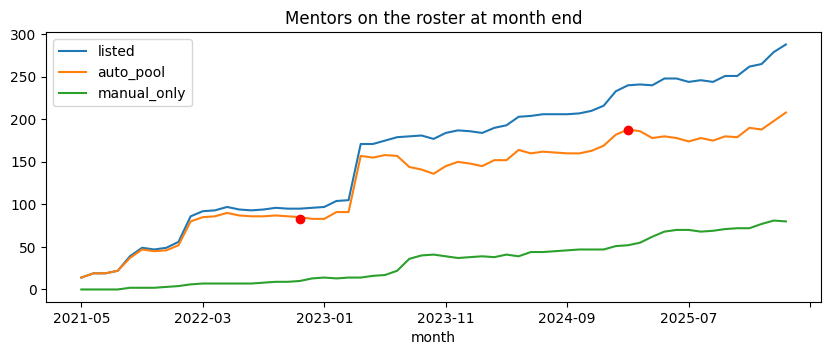

In [15]:
display(mp.loc[["2021-05", "2021-09", "2022-10", "2022-11", "2023-11", "2024-06", "2025-02", "2026-03"]])
ax = mp.plot(figsize=(10, 3.5), title="Mentors on the roster at month end")
ax.scatter([mp.index.get_loc("2022-11"), mp.index.get_loc("2025-02")], [83, 187], color="red", zorder=5, label="public figures")
print("period length in days (closed periods):")
print((periods.hours.dropna() / 24).describe().round(1).to_string())

**What the output shows.** The roster grew from 14 mentors in 2021-05 to 288 in 2026-03. The automatic
pool had 85 mentors in 2022-11 and 188 in 2025-02, within 2 and 1 of the public figures (83 and 187),
so the rebuild agrees with outside numbers. The manual-only group grew too, to 80 in 2026-03. Periods
vary a lot: the median closed period is 80 days, but a quarter last under 2.6 days (the minimum shows as
0.0 because of the short test edits from section 6).

## 8. Summary (written to results/m1_report.json, read by M9)

**What this checks.** It writes the key numbers to a small report file that the paper step (M9) reads,
and prints the total of passed checks.

In [16]:
report = {"n_mentors": len(ml), "n_current": int(ml.is_current.sum()),
          "n_current_auto": int((ml.currently_in_auto_pool == True).sum()),
          "n_ever_manual_only": int(ml.ever_manual_only.sum()),
          "auto_pool_2022_11": int(mp.loc["2022-11", "auto_pool"]), "auto_pool_2025_02": int(mp.loc["2025-02", "auto_pool"]),
          "differs_from_eval2": int((cmp.kind != "same").sum())}
(config.RESULTS / "m1_report.json").write_text(json.dumps(report, indent=1))
print(json.dumps(report, indent=1))
print(f"\nchecks passed: {sum(ok for _, ok in ck.items)} / {len(ck.items)}; "
      f"random and tracer mentors matching the replay: {sum(rand_ok) + sum(tracer_ok)} / {len(rand_ok) + len(tracer_ok)}")

{
 "n_mentors": 450,
 "n_current": 291,
 "n_current_auto": 210,
 "n_ever_manual_only": 162,
 "auto_pool_2022_11": 85,
 "auto_pool_2025_02": 188,
 "differs_from_eval2": 11
}

checks passed: 35 / 35; random and tracer mentors matching the replay: 22 / 22


**What the output shows.** On the final data (cutoff 2026-04-20T14:00Z): 450 mentors, 291 still on the
roster at the cutoff (210 in the automatic pool), 162 manual only at some time, and 11 small date
differences from eval2, all explained. All 35 of 35 checks pass, and all 22 tracer and random mentors
match the independent replay. M1 can be trusted as the input for M2 and M4.